## upload and unzip dataset

In [1]:
!unzip all_input_outputs_to_model.zip

Archive:  all_input_outputs_to_model.zip
   creating: all_input_outputs_to_model/
  inflating: all_input_outputs_to_model/0000_json_1_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_2_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_3_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_4_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_5_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_6_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_7_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_8_phase_2.json  


In [2]:
%ls all_input_outputs_to_model/

0000_json_1_phase_2.json  0000_json_4_phase_2.json  0000_json_7_phase_2.json
0000_json_2_phase_2.json  0000_json_5_phase_2.json  0000_json_8_phase_2.json
0000_json_3_phase_2.json  0000_json_6_phase_2.json


##  1. Install dependencies

In [3]:
!pip install torch transformers datasets sentence-transformers scikit-learn -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 69.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 109.7 MB/s eta 0:00:00


## 2. Load and preprocess your dataset

### get familiar with dataset, perform analysis and find the good MAX_LENGTH

In [ ]:
import json
import os
from pathlib import Path

data_dir = Path("all_input_outputs_to_model")
texts, questions = [], []

for file in data_dir.glob("*.json"):
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)
        for item in data:
            text = item["textual_content_response"]
            texts.append(text)
            for qa in item["question_and_answer_response"]["questions_and_answers"]:
                questions.append((qa["question"], text))  # (question, related_text)

len(questions), len(texts)

(52036, 10410)

In [ ]:
import pandas as pd

# Step 1: Convert the array of tuples into a pandas DataFrame
df = pd.DataFrame(questions, columns=['question', 'related_text'])
df.head(10)

,question,related_text
0,ابواسحاق جویباری چه شغل‌هایی داشت؟,ابواسحاق جویباری مردی زرگر و شاعر بود. او که ب...
1,ابواسحاق جویباری در کدام دوره تاریخی می‌زیسته ...,ابواسحاق جویباری مردی زرگر و شاعر بود. او که ب...
2,ابواسحاق جویباری در کدام شهر متولد شده است؟,ابواسحاق جویباری مردی زرگر و شاعر بود. او که ب...
3,مقبره ابواسحاق جویباری در کجا قرار دارد؟,ابواسحاق جویباری مردی زرگر و شاعر بود. او که ب...
4,ابواسحاق جویباری در چه زمینه‌ای از پیشگامان بو...,ابواسحاق جویباری مردی زرگر و شاعر بود. او که ب...
5,ابوحفص سغدی در چه سده‌ای می‌زیست؟,ابوحفص سغدی، که با نام‌های غضایری و ابوحفض نیز...
6,ابوحفص سغدی در کدام منطقه متولد شد؟,ابوحفص سغدی، که با نام‌های غضایری و ابوحفض نیز...
7,ابوحفص سغدی به عنوان یکی از پیشگامان چه چیزی ش...,ابوحفص سغدی، که با نام‌های غضایری و ابوحفض نیز...
8,کدام ساز به ابوحفص سغدی نسبت داده می‌شود؟,ابوحفص سغدی، که با نام‌های غضایری و ابوحفض نیز...
9,نام‌های دیگر ابوحفص سغدی چه بود؟,ابوحفص سغدی، که با نام‌های غضایری و ابوحفض نیز...


In [ ]:
# Find the maximum and average lengths for each column
max_question_length = df['question'].str.len().max()
avg_question_length = df['question'].str.len().mean()

max_related_text_length = df['related_text'].str.len().max()
avg_related_text_length = df['related_text'].str.len().mean()

# Print the results
print(f"Maximum length of 'question': {max_question_length}")
print(f"Average length of 'question': {avg_question_length:.2f}")

print(f"Maximum length of 'related_text': {max_related_text_length}")
print(f"Average length of 'related_text': {avg_related_text_length:.2f}")

Maximum length of 'question': 153
Average length of 'question': 47.75
Maximum length of 'related_text': 5852
Average length of 'related_text': 451.59


because of the much data we can filter with less than 512

In [ ]:
df.count()

,0
question,52036
related_text,52036


In [ ]:
# Step 2: Save the DataFrame to a file (e.g., CSV, JSON)
file_path = 'questions_texts_dataset_csv.csv'  # Specify the file path
df.to_csv(file_path, index=False, encoding='utf-8')  # Save without the index column
print("DataFrame saved successfully as CSV.")

file_path = 'questions_texts_dataset_json.json'  # Specify the file path
df.to_json(file_path, orient='records', force_ascii=False, indent=4)  # Save as JSON
print("DataFrame saved successfully as JSON.")

DataFrame saved successfully as CSV.
DataFrame saved successfully as JSON.


In [ ]:
!zip questions_texts_dataset_csv.zip questions_texts_dataset_csv.csv
!zip questions_texts_dataset_json.zip questions_texts_dataset_json.json

updating: questions_texts_dataset_csv.csv (deflated 93%)
updating: questions_texts_dataset_json.json (deflated 94%)


In [ ]:
%ls -l

total 100780
drwxr-xr-x 2 root root     4096 Jul 31 16:46 all_input_outputs_to_model/
-rw-r--r-- 1 root root 46846848 Aug  1 08:37 questions_texts_dataset_csv.csv
-rw-r--r-- 1 root root  3135840 Aug  1 08:37 questions_texts_dataset_csv.zip
-rw-r--r-- 1 root root 50004304 Aug  1 08:37 questions_texts_dataset_json.json
-rw-r--r-- 1 root root  3186008 Aug  1 08:37 questions_texts_dataset_json.zip
drwxr-xr-x 1 root root     4096 Jul 30 13:39 sample_data/


In [ ]:
# # Load the saved file back into a pandas DataFrame
# loaded_df = pd.read_csv(file_path, encoding='utf-8')  # Ensure UTF-8 encoding

# # Display the loaded DataFrame
# print("\nLoaded DataFrame:")
# print(loaded_df)

# # Load the saved JSON file back into a pandas DataFrame
# loaded_df = pd.read_json(file_path, orient='records')

# # Display the loaded DataFrame
# print("\nLoaded DataFrame:")
# print(loaded_df)

In [ ]:
# filtered_df = df[df['related_text'].str.len() <= 512] # 38156
filtered_df = df[df['related_text'].str.len() <= 160] # 13316

print("Filtered DataFrame Count:")
print(filtered_df.count())

# Print the filtered DataFrame
print("Filtered DataFrame:")
filtered_df

Filtered DataFrame Count:
question        13316
related_text    13316
dtype: int64
Filtered DataFrame:


,question,related_text
190,قمری جرجانی در کدام شهر متولد شد؟,قمری جرجانی، شاعر ایرانی، در جرجان متولد شد. ا...
191,قمری جرجانی همدوره چه کسی بود؟,قمری جرجانی، شاعر ایرانی، در جرجان متولد شد. ا...
192,قمری جرجانی در چه شهری درگذشت؟,قمری جرجانی، شاعر ایرانی، در جرجان متولد شد. ا...
193,مقبره قمری جرجانی در کجا قرار دارد؟,قمری جرجانی، شاعر ایرانی، در جرجان متولد شد. ا...
194,قمری جرجانی چه نقشی در رابطه با قابوس وشمگیر د...,قمری جرجانی، شاعر ایرانی، در جرجان متولد شد. ا...
...,...,...
51986,مژگان عظیمی چه نوع شخصیتی است؟,مژگان عظیمی یک شخصیت شناخته شده است.
51987,نام کامل شخصیت مورد بحث چیست؟,مژگان عظیمی یک شخصیت شناخته شده است.
51988,شهرت مژگان عظیمی در چه زمینه‌ای است؟,مژگان عظیمی یک شخصیت شناخته شده است.
51989,مژگان عظیمی در چه سالی متولد شده است؟,مژگان عظیمی یک شخصیت شناخته شده است.


In [ ]:
file_path = 'questions_texts_dataset_maxlen_160_json.json'  # Specify the file path
filtered_df.to_json(file_path, orient='records', force_ascii=False, indent=4)  # Save as JSON
print("DataFrame saved successfully as JSON.")

!zip questions_texts_dataset_maxlen_160_json.zip questions_texts_dataset_maxlen_160_json.json

DataFrame saved successfully as JSON.
  adding: questions_texts_dataset_maxlen_160_json.json (deflated 94%)


In [ ]:
filtered_df = df[df['related_text'].str.len() <= 256] # 25911

print("Filtered DataFrame Count:")
print(filtered_df.count()) # as discussed in the telegram group we need about 10k samples for training in this we we would have 25k

# Print the filtered DataFrame
print("Filtered DataFrame:")
filtered_df

Filtered DataFrame Count:
question        25911
related_text    25911
dtype: int64
Filtered DataFrame:


,question,related_text
50,محمد بن مخلد سگزی در کدام منطقه متولد شد؟,محمد بن مخلد سگزی مردی شاعر بود که در سیستان م...
51,محمد بن مخلد سگزی در دوران کدام سلسله می‌زیست؟,محمد بن مخلد سگزی مردی شاعر بود که در سیستان م...
52,از محمد بن مخلد سگزی چه شعری به جا مانده است؟,محمد بن مخلد سگزی مردی شاعر بود که در سیستان م...
53,محمد بن مخلد سگزی از چه جهت اهمیت دارد؟,محمد بن مخلد سگزی مردی شاعر بود که در سیستان م...
54,محمد بن مخلد سگزی در کدام شهر اقامت داشت؟,محمد بن مخلد سگزی مردی شاعر بود که در سیستان م...
...,...,...
51996,ایرج دوستدار در چه سالی و در کدام شهر متولد شد؟,ایرج دوستدار مردی بود که در تاریخ سوم اسفند ما...
51997,ایرج دوستدار در چه سالی و در کدام شهر درگذشت؟,ایرج دوستدار مردی بود که در تاریخ سوم اسفند ما...
51998,ایرج دوستدار در چه زمینه‌هایی فعالیت می‌کرد؟,ایرج دوستدار مردی بود که در تاریخ سوم اسفند ما...
51999,تاریخ دقیق تولد ایرج دوستدار چه بود؟,ایرج دوستدار مردی بود که در تاریخ سوم اسفند ما...


### reduce dataset size to 13k with condition "MAX_LENGTH = 160"
We did this because as discussed in the NLP group we need to train our model roughly for 10k samples.

In [4]:
MAX_LENGTH = 160

In [5]:
import json
import os
from pathlib import Path

data_dir = Path("all_input_outputs_to_model")
texts, questions = [], []

for file in data_dir.glob("*.json"):
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)
        for item in data:
            text = item["textual_content_response"]
            if len(text) <= MAX_LENGTH:
                texts.append(text)
                for qa in item["question_and_answer_response"]["questions_and_answers"]:
                    questions.append((qa["question"], text))  # (question, related_text)

print("#questions", "\t", "#texts")
print(len(questions), "\t\t", len(texts))

#questions 	 #texts
13316 		 2666


## 3. Prepare Dataset for Contrastive Learning

In [6]:
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

model_name = "cis-lmu/glot500-base"  # HF GLOT500 model name
tokenizer = AutoTokenizer.from_pretrained(model_name)

class QATextDataset(Dataset):
    def __init__(self, pairs, tokenizer, max_len=MAX_LENGTH):
        self.pairs = pairs
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        q, t = self.pairs[idx]
        q_enc = tokenizer(q, truncation=True, padding='max_length', max_length=self.max_len, return_tensors="pt")
        t_enc = tokenizer(t, truncation=True, padding='max_length', max_length=self.max_len, return_tensors="pt")
        return q_enc, t_enc

dataset = QATextDataset(questions, tokenizer)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True) # batch_size=32 -> GPU RAM 12.5 / 15.0 GB


tokenizer_config.json:   0%|          | 0.00/496 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/7.66M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

## 3.5 Run MLM pre-training (optional but recommended).

Optional: Pre-train with Masked Language Modeling (MLM)

Before contrastive training, we could run MLM on texts to adapt GLOT500 better to Persian:


In [ ]:
# from transformers import DataCollatorForLanguageModeling, Trainer, TrainingArguments

# mlm_dataset = tokenizer(texts, truncation=True, padding="max_length", max_length=MAX_LENGTH, return_tensors="pt")
# data_collator = DataCollatorForLanguageModeling(tokenizer, mlm_probability=0.15)
# training_args = TrainingArguments("glot500_mlm", per_device_train_batch_size=32, num_train_epochs=2)
# trainer = Trainer(model=AutoModel.from_pretrained(model_name), args=training_args, data_collator=data_collator, train_dataset=mlm_dataset)
# trainer.train()


# --- MLM Pre-training ---
from transformers import DataCollatorForLanguageModeling, Trainer, TrainingArguments, AutoModelForMaskedLM
import torch
import torch.nn as nn

# Create MLM dataset (tokenized texts)
mlm_inputs = tokenizer(texts, truncation=True, padding="max_length", max_length=MAX_LENGTH)
mlm_dataset = torch.utils.data.TensorDataset(
    torch.tensor(mlm_inputs["input_ids"]),
    torch.tensor(mlm_inputs["attention_mask"])
)

class MLMDataset(torch.utils.data.Dataset):
    def __init__(self, encodings):
        self.encodings = encodings
    def __len__(self):
        return len(self.encodings["input_ids"])
    def __getitem__(self, idx):
        return {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}

mlm_dataset = MLMDataset(mlm_inputs)

# Define MLM model
mlm_model = AutoModelForMaskedLM.from_pretrained(model_name)

data_collator = DataCollatorForLanguageModeling(tokenizer, mlm_probability=0.15)

training_args = TrainingArguments(
    output_dir="glot500_mlm",
    per_device_train_batch_size=8,
    num_train_epochs=2,
    save_strategy="epoch",
    logging_steps=100,
    report_to="none"  # disables wandb, tensorboard, etc.
)

trainer = Trainer(
    model=mlm_model,
    args=training_args,
    data_collator=data_collator,
    train_dataset=mlm_dataset
)

trainer.train()

# Save MLM-adapted model
trainer.save_model("glot500_mlm_adapted")
del mlm_model
torch.cuda.empty_cache()

/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1750: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `XLMRobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)


Step,Training Loss
100,1.629700
200,1.388300
300,1.329800
400,1.159000
500,1.163700
600,1.099900


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1750: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `XLMRobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)


## 4. Build Contrastive Training Model

In [7]:
import torch
import torch.nn as nn
from transformers import AutoModel

class DualEncoder(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        # self.encoder = AutoModel.from_pretrained(model_name)
        self.encoder = AutoModel.from_pretrained(model_name, add_pooling_layer=False)
        self.proj = nn.Linear(self.encoder.config.hidden_size, 256)  # projection head

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        pooled = out.last_hidden_state[:, 0]  # CLS token
        return self.proj(pooled)

# using base model
# model = DualEncoder(model_name).cuda()

# using MLM pretrained model
mlm_adapted_path = "glot500_mlm_adapted"
model = DualEncoder(mlm_adapted_path).cuda()  # Instead of base GLOT500

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.58G [00:00<?, ?B/s]

## 5. Contrastive Loss

In [8]:
import torch.nn.functional as F

def contrastive_loss(q_emb, t_emb, temperature=0.05):
    sim_matrix = F.cosine_similarity(q_emb.unsqueeze(1), t_emb.unsqueeze(0), dim=2)
    labels = torch.arange(sim_matrix.size(0)).to(q_emb.device)
    loss = F.cross_entropy(sim_matrix / temperature, labels)
    return loss


## 6. Training Loop

### main loop

In [9]:
from tqdm import tqdm
import matplotlib.pyplot as plt

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
model.train()

NUM_EPOCHS = 5
losses = []  # To track loss per iteration

for epoch in range(NUM_EPOCHS):
    model.train()
    total_loss = 0
    progress_bar = tqdm(dataloader, desc=f"Epoch {epoch+1}", leave=False)

    for q_enc, t_enc in progress_bar:
        q_ids, q_mask = q_enc['input_ids'].squeeze(1).cuda(), q_enc['attention_mask'].squeeze(1).cuda()
        t_ids, t_mask = t_enc['input_ids'].squeeze(1).cuda(), t_enc['attention_mask'].squeeze(1).cuda()

        q_emb = model(q_ids, q_mask)
        t_emb = model(t_ids, t_mask)

        loss = contrastive_loss(q_emb, t_emb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Track loss
        losses.append(loss.item())

        total_loss += loss.item()
        progress_bar.set_postfix({"batch_loss": f"{loss.item():.4f}"})

    print(f"Epoch {epoch+1}, Avg Loss: {total_loss/len(dataloader):.4f}")

torch.save(model.state_dict(), "glot500_finetuned.pth")

Epoch 1:   0%|          | 0/417 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1750: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `XLMRobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)


Epoch 1, Avg Loss: 3.0066


Epoch 2, Avg Loss: 0.2892


Epoch 3, Avg Loss: 0.1764


Epoch 4, Avg Loss: 0.1358


Epoch 5, Avg Loss: 0.1173


### Plot the Loss Curve:

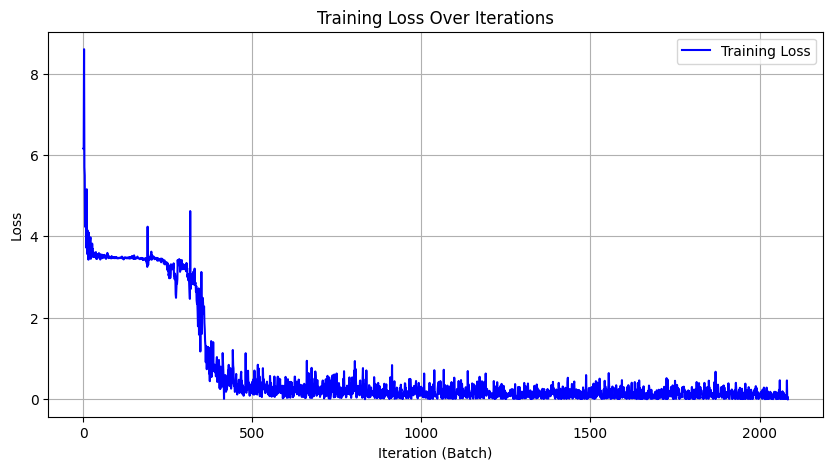

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(losses, label="Training Loss", color="blue")
plt.xlabel("Iteration (Batch)")
plt.ylabel("Loss")
plt.title("Training Loss Over Iterations")
plt.legend()
plt.grid(True)
plt.show()

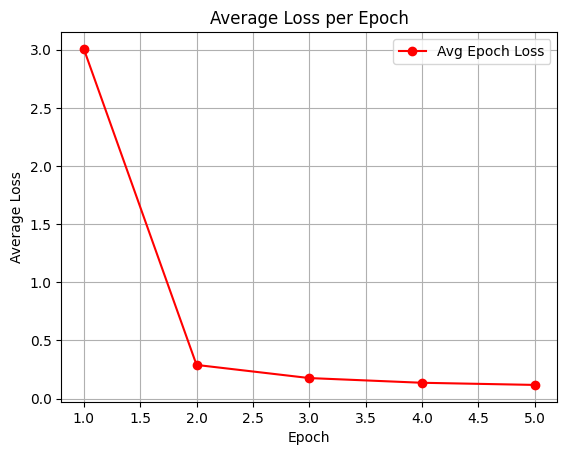

In [11]:
epoch_avg_losses = [sum(losses[i*len(dataloader):(i+1)*len(dataloader)]) / len(dataloader) for i in range(NUM_EPOCHS)]
plt.plot(range(1, NUM_EPOCHS+1), epoch_avg_losses, marker='o', color='red', label="Avg Epoch Loss")
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.title("Average Loss per Epoch")
plt.legend()
plt.grid(True)
plt.show()

## 7. Evaluation

### Load questions.json

In [13]:
with open("questions.json", "r", encoding="utf-8") as f:
    eval_questions = json.load(f)


### (a) TF-IDF Retrieval

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

vectorizer = TfidfVectorizer()
tfidf_texts = vectorizer.fit_transform(texts)

def retrieve_tfidf(query, top_k=3):
    q_vec = vectorizer.transform([query])
    scores = (q_vec @ tfidf_texts.T).toarray()[0]
    top_idx = np.argsort(scores)[::-1][:top_k]
    return [texts[i] for i in top_idx]


### (b) Zero-Shot GLOT500 & (c) Fine-tuned GLOT500

In [15]:
def encode_texts(model, data):
    encs = []
    for d in data:
        tok = tokenizer(d, return_tensors="pt", truncation=True, padding="max_length", max_length=MAX_LENGTH).to("cuda")
        with torch.no_grad():
            emb = model(tok["input_ids"], tok["attention_mask"])
        encs.append(emb.cpu())
    return torch.stack(encs).squeeze()

# Zero-shot embeddings
base_encoder = DualEncoder(model_name).cuda().eval()
base_text_embs = encode_texts(base_encoder, texts)

# Fine-tuned embeddings
model.eval()
# model.load_state_dict(torch.load("glot500_finetuned.pth"))
ft_text_embs = encode_texts(model, texts)

def retrieve_nn(query, encoder, text_embs, top_k=3):
    tok = tokenizer(query, return_tensors="pt", truncation=True, padding="max_length", max_length=256).to("cuda")
    with torch.no_grad():
        q_emb = encoder(tok["input_ids"], tok["attention_mask"]).cpu()
    sims = F.cosine_similarity(q_emb, text_embs)
    top_idx = torch.topk(sims, top_k).indices
    return [texts[i] for i in top_idx]


### Run All Models

In [16]:
results = {}

for q_item in eval_questions:
    question_text = q_item["question"]
    results[question_text] = {
        "tfidf": retrieve_tfidf(question_text),
        "glot500_zero_shot": retrieve_nn(question_text, base_encoder, base_text_embs),
        "glot500_finetuned": retrieve_nn(question_text, model, ft_text_embs)
    }

In [17]:
import json
with open("retrieval_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=4)

## 8. print the results

In [18]:
for question, result in results.items():
    print(f"question: {question}")
    print("tf-idf:")
    for j in range(len(result['tfidf'])):
        print(f"{j+1}. {result['tfidf'][j]}")
    print("glot500_zero_shot:")
    for j in range(len(result['glot500_zero_shot'])):
        print(f"{j+1}. {result['glot500_zero_shot'][j]}")
    print("glot500_finetuned:")
    for j in range(len(result['glot500_finetuned'])):
        print(f"{j+1}. {result['glot500_finetuned'][j]}")
    print("-"*50)

question: مصطفی کتیرایی در چه شهری درگذشت؟
tf-idf:
1. مصطفی کتیرایی سیاستمدار و وکیل بود. او در تاریخ ۱ فروردین ۱۳۰۷ در ملایر، همدان متولد شد. کتیرایی در تاریخ ۱۲ اسفند ۱۳94 در تهران درگذشت.
2. مصطفی هاشمی مرد و در رشته بسکتبال فعالیت می‌کند.
3. مصطفی مهدوی مردی است که در ایران متولد شده و در رشته ورزشی فوتبال فعالیت می‌کند.
glot500_zero_shot:
1. مرتضی نیک نژاد در تاریخ ۱۳۲۱/۰۵/۰۴ در شهر تهران، استان تهران متولد شد. او در تاریخ ۱۳۴۴/۰۵/۰۴ درگذشت. مرتضی نیک نژاد عضو ائتلاف اسلامی بود.
2. وحشتی جوشقانی در گلکنده درگذشت. او در دوره صفویه می‌زیست و شاعر بود. وحشتی جوشقانی در سال ۹۹۹ در شیراز رویدادی را تجربه کرد.
3. بهرام شفیع در تاریخ ۲۹ اردیبهشت ۱۳۳۵ در تهران متولد شد. او در تاریخ ۱۷ مهر ۱۳۹۷ درگذشت. بهرام شفیع در رشته فوتبال فعالیت می‌کرد.
glot500_finetuned:
1. مصطفی کتیرایی سیاستمدار و وکیل بود. او در تاریخ ۱ فروردین ۱۳۰۷ در ملایر، همدان متولد شد. کتیرایی در تاریخ ۱۲ اسفند ۱۳94 در تهران درگذشت.
2. مصطفی پورمحمدی در تاریخ ۱۳۳۹/۰۶/۱۲ در شهر قم، استان قم متولد شده است. او روحانی، مقام ساب

## 9. Zip the results and make them ready for download


In [19]:
!zip retrieval_results.zip retrieval_results.json

  adding: retrieval_results.json (deflated 88%)
